# Qatar Import Trade Data Lakehouse (2017–2024)

**Dataset:** CEPII BACI HS17  
**Architecture:** Bronze → Silver → Gold  
**Focus:** Qatar's imports from 2017 to 2024

This notebook documents the ingestion, cleaning, dimensional modeling,
and analysis of Qatar's international merchandise imports.

In [1]:
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Both imports successful!")

NumPy: 2.5.3
Pandas: 3.0.6
Both imports successful!


## 1. Bronze Layer — Raw Data Ingestion

The Bronze layer stores the original BACI HS17 trade records
from 2017 to 2024.

All source columns are preserved as strings, and ingestion
metadata is added to support traceability and auditing.

### Ingestion Strategy

**Ingestion approach:** The project uses batch ingestion because CEPII BACI data is distributed as annual CSV files rather than a continuous event stream. The pipeline uses a pull-based approach, reading files from the local `data/raw/BACI_HS17/` directory after they have been downloaded from the CEPII website.

**Initial load:** The first execution performs a full historical load of the eight annual BACI HS17 files covering 2017–2024.

**Incremental loading:** Subsequent executions check the `bronze.load_log` table to identify files that have already been processed. Files recorded as successfully loaded are skipped, while new files can be ingested without reloading the complete historical dataset.

**Frequency:** Ingestion is performed when a new annual BACI release becomes available or when the source files need to be refreshed. Continuous or real-time ingestion is unnecessary for this dataset.

**Watermark:** The ingestion log acts as a file-level processing watermark by tracking source filenames and their ingestion status. This is different from an event-time watermark because the source consists of complete annual files.

**Failure recovery and reruns:** If ingestion is interrupted, the load log helps identify which files were successfully processed. The pipeline can then be rerun to skip completed files and process remaining files. The Silver and Gold pipelines rebuild their outputs from the stored data, avoiding accumulated duplicates during reruns.

**Data lineage:** Each Bronze record includes `source_name`, `ingested_at`, and `load_id`, allowing records to be traced back to their source file and ingestion run.

In [4]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

LAKEHOUSE_DIR = BASE_DIR / "lakehouse"

con = duckdb.connect(str(LAKEHOUSE_DIR / "connection.duckdb"))
con.execute("LOAD ducklake;")

catalog_path = (LAKEHOUSE_DIR / "catalog.ducklake").as_posix()
storage_path = (LAKEHOUSE_DIR / "storage").as_posix() + "/"

con.execute(f"""
    ATTACH 'ducklake:{catalog_path}' AS lake
    (DATA_PATH '{storage_path}');
""")

print("Connected to DuckLake successfully!")

Connected to DuckLake successfully!


In [5]:
bronze_summary = con.execute("""
    SELECT
        source_name,
        SUM(input_row_count) AS total_rows
    FROM lake.bronze.load_log
    GROUP BY source_name
    ORDER BY source_name
""").df()

display(bronze_summary)

print(
    "Total Bronze records:",
    f"{bronze_summary['total_rows'].sum():,}"
)

,source_name,total_rows
0,BACI_HS17_Y2017_V202601.csv,9948845.0
1,BACI_HS17_Y2018_V202601.csv,10802500.0
2,BACI_HS17_Y2019_V202601.csv,11210131.0
3,BACI_HS17_Y2020_V202601.csv,10985158.0
4,BACI_HS17_Y2021_V202601.csv,11598685.0
5,BACI_HS17_Y2022_V202601.csv,11703117.0
6,BACI_HS17_Y2023_V202601.csv,11781215.0
7,BACI_HS17_Y2024_V202601.csv,11177570.0


Total Bronze records: 89,207,221.0


## 2. Silver Layer — Data Cleaning and Quality Validation

The Silver layer filters the Bronze dataset to Qatar imports
(importer code 634) from 2017 to 2024.

It validates years, country codes, product codes, trade values,
and quantities, and checks for duplicate business keys.

Missing quantities are retained as NULL because the corresponding
trade values are still useful for analysis. Invalid records are
stored in a quarantine table.

The quality report summarizes the cleaning results.

In [6]:
silver_quality = con.execute("""
    SELECT
        metric,
        metric_value
    FROM lake.silver.quality_report
    ORDER BY metric
""").df()

display(silver_quality)

,metric,metric_value
0,bronze_qatar_rows,467811
1,bronze_total_rows,89207221
2,duplicate_rows,0
3,null_key_rows,0
4,quarantine_rows,0
5,silver_duplicate_keys,0
6,silver_null_quantity,11278
7,silver_valid_rows,467811


## 3. Gold Layer — Dimensional Modeling

The Gold layer organizes Qatar's cleaned import records into a star schema
containing one fact table and three dimension tables.

**Fact table:** `fact_imports`

**Dimension tables:**
- `dim_year`: Year information.
- `dim_exporter`: Exporter country names and ISO3 codes.
- `dim_product`: HS17 product codes and descriptions.

**Fact table grain:** One row represents the import of one HS17 product
from one exporter country into Qatar during one year.

The fact table stores trade value and quantity, with foreign keys
referencing the three dimensions.

In [7]:
gold_counts = con.execute("""
    SELECT 'dim_year' AS table_name, COUNT(*) AS row_count
    FROM lake.gold.dim_year

    UNION ALL

    SELECT 'dim_exporter', COUNT(*)
    FROM lake.gold.dim_exporter

    UNION ALL

    SELECT 'dim_product', COUNT(*)
    FROM lake.gold.dim_product

    UNION ALL

    SELECT 'fact_imports', COUNT(*)
    FROM lake.gold.fact_imports
""").df()

display(gold_counts)

,table_name,row_count
0,dim_year,8
1,dim_exporter,169
2,dim_product,5173
3,fact_imports,467811


### Gold Star Schema Diagram

The following diagram illustrates the Gold layer's dimensional model,
consisting of one fact table and three dimension tables.

![Gold Star Schema](../diagrams/star_schema.png)

**Fact table grain:** One row per year, exporter country, and HS17 product imported into Qatar.

**Relationships:**
- `fact_imports.year_key` → `dim_year.year_key`
- `fact_imports.exporter_key` → `dim_exporter.exporter_key`
- `fact_imports.product_key` → `dim_product.product_key`

Primary-key uniqueness and foreign-key integrity were verified
during Gold pipeline execution.

## 4. Data Analysis — Gold Layer

All four analytical questions are answered using Gold-layer tables only.

### Question 1: How did Qatar's total import value change from 2017 to 2024?

This query calculates Qatar's annual import value by summing trade
values from the Gold fact table and joining the year dimension.

,year,total_import_value
0,2017,22647187.65
1,2018,28491365.70
2,2019,30582883.76
3,2020,30357095.12
4,2021,32628451.07
5,2022,39673403.22
6,2023,37813395.55
7,2024,37134679.73


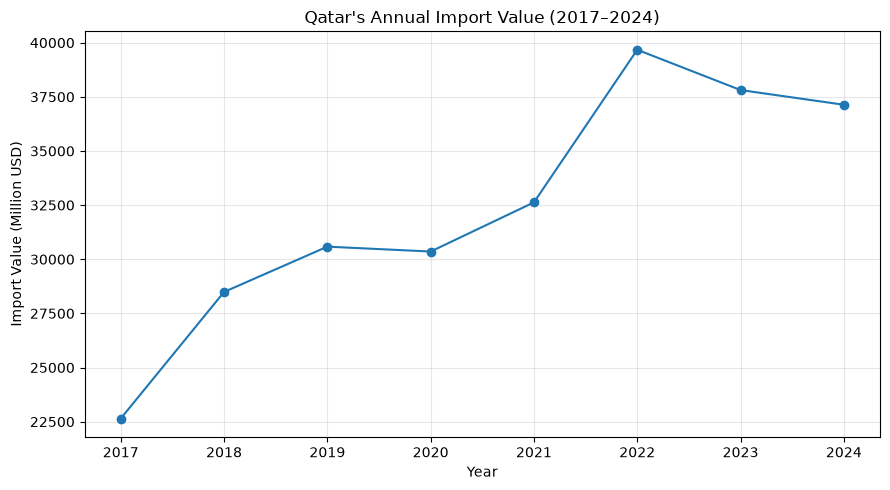

In [8]:
# Question 1: Qatar's annual import value
q1 = con.execute("""
    SELECT
        y.year,
        ROUND(SUM(f.trade_value), 2) AS total_import_value
    FROM lake.gold.fact_imports f
    JOIN lake.gold.dim_year y
        ON f.year_key = y.year_key
    GROUP BY y.year
    ORDER BY y.year
""").df()

display(q1)

# Visualization 1
plt.figure(figsize=(9, 5))
plt.plot(
    q1["year"],
    q1["total_import_value"] / 1000,
    marker="o"
)

plt.title("Qatar's Annual Import Value (2017–2024)")
plt.xlabel("Year")
plt.ylabel("Import Value (Million USD)")
plt.xticks(q1["year"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation — Question 1**

Qatar's total import value increased from approximately **$22.65 billion in 2017** to **$37.13 billion in 2024**, representing an overall increase of approximately **64%**. Import value generally increased throughout the period, reaching its highest level of approximately **$39.67 billion in 2022**. A slight decline occurred in 2020 compared with 2019, followed by a strong recovery in 2021 and 2022. Import values decreased in 2023 and 2024 but remained substantially higher than in 2017. Overall, the results indicate long-term growth in Qatar's merchandise import value, although annual fluctuations occurred.

### Question 2: Which 10 countries supplied Qatar with the highest import value?

This query identifies the ten largest exporter countries supplying Qatar
between 2017 and 2024, ranked by their total trade value.

It joins the Gold fact table with the exporter dimension to display
country names instead of numeric country codes.

,exporter_country,total_import_value
0,China,29446689.57
1,USA,26697133.70
2,United Kingdom,22096966.94
3,France,16375844.08
4,United Arab Emirates,13320660.64
5,India,13309943.14
6,Germany,13133309.75
7,Italy,12313490.03
8,Oman,10382016.68
9,Japan,9363254.58


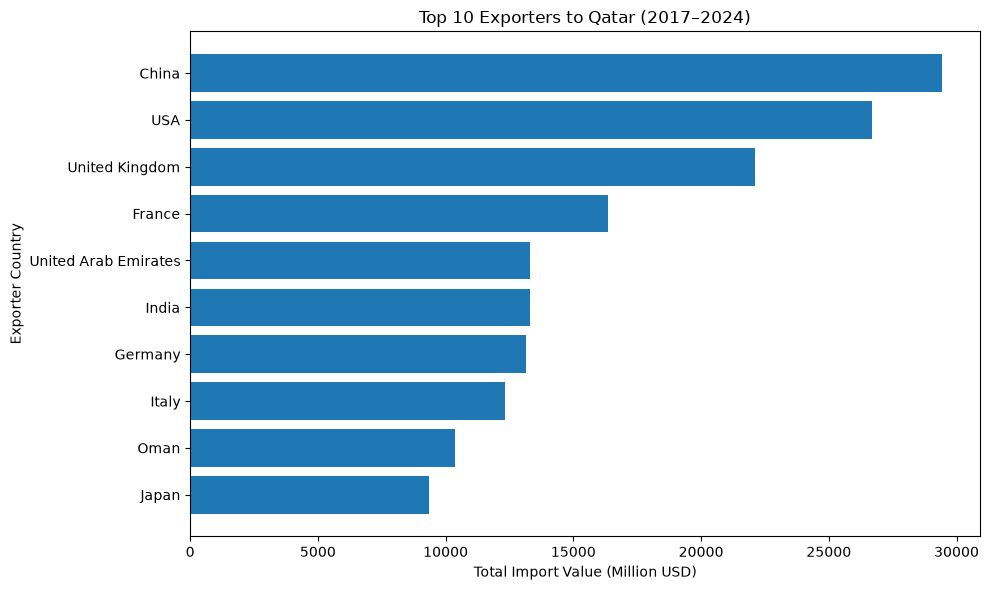

In [9]:
# Question 2: Top 10 exporter countries
q2 = con.execute("""
    SELECT
        e.country_name AS exporter_country,
        ROUND(SUM(f.trade_value), 2) AS total_import_value
    FROM lake.gold.fact_imports f
    JOIN lake.gold.dim_exporter e
        ON f.exporter_key = e.exporter_key
    GROUP BY e.exporter_key, e.country_name
    ORDER BY total_import_value DESC
    LIMIT 10
""").df()

display(q2)

# Visualization 2: Horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    q2["exporter_country"],
    q2["total_import_value"] / 1000
)

plt.gca().invert_yaxis()
plt.title("Top 10 Exporters to Qatar (2017–2024)")
plt.xlabel("Total Import Value (Million USD)")
plt.ylabel("Exporter Country")
plt.tight_layout()
plt.show()

**Interpretation — Question 2**

China was Qatar's largest exporter by total import value between 2017 and 2024, accounting for approximately **$29.45 billion**, followed by the United States (**$26.70 billion**) and the United Kingdom (**$22.10 billion**). France ranked fourth with approximately **$16.38 billion**, while the United Arab Emirates ranked fifth with **$13.32 billion**. Other major suppliers included India, Germany, Italy, Oman, and Japan. These findings indicate that Qatar sourced high-value imports from a diverse range of countries across Asia, Europe, North America, and the Middle East. China held the leading position over the eight-year period, although the results represent cumulative import values rather than annual rankings.

### Question 3: Which 10 HS17 products accounted for the highest import value?

This query identifies Qatar's ten highest-value imported HS17 products
between 2017 and 2024.

It joins the Gold fact table with the product dimension to display
six-digit HS17 codes and their corresponding product descriptions.

,hs17_code,product,total_import_value
0,841112,Turbo-jets: of a thrust exceeding 25kN,13412014.44
1,711319,Jewellery: of precious metal (excluding silver...,10215626.19
2,880240,Aeroplanes and other aircraft: of an unladen w...,9334376.66
3,870324,Vehicles: with only spark-ignition internal co...,5516226.18
4,851712,Telephones for cellular networks or for other ...,3874848.62
5,880330,Aircraft and spacecraft: parts of aeroplanes o...,3671756.96
6,870323,Vehicles: with only spark-ignition internal co...,3137593.45
7,710812,"Metals: gold, non-monetary, unwrought (but not...",3090744.53
8,300490,Medicaments: consisting of mixed or unmixed pr...,3080198.01
9,271000,Petroleum oils and oils from bituminous minera...,2763942.04


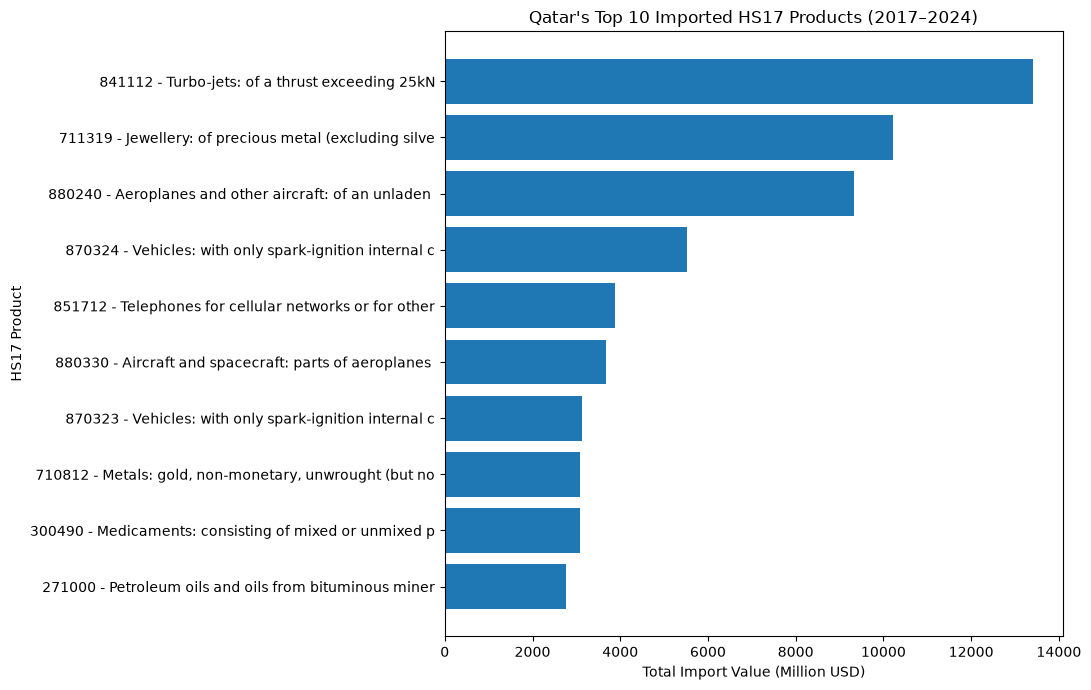

In [10]:
# Question 3: Top 10 imported HS17 products
q3 = con.execute("""
    SELECT
        p.product_key AS hs17_code,
        p.product_description AS product,
        ROUND(SUM(f.trade_value), 2) AS total_import_value
    FROM lake.gold.fact_imports f
    JOIN lake.gold.dim_product p
        ON f.product_key = p.product_key
    GROUP BY p.product_key, p.product_description
    ORDER BY total_import_value DESC
    LIMIT 10
""").df()

display(q3)

# Visualization 3: Horizontal bar chart
plt.figure(figsize=(11, 7))

labels = [
    f"{row.hs17_code} - {row.product[:45]}"
    for row in q3.itertuples()
]

plt.barh(
    labels,
    q3["total_import_value"] / 1000
)

plt.gca().invert_yaxis()
plt.title("Qatar's Top 10 Imported HS17 Products (2017–2024)")
plt.xlabel("Total Import Value (Million USD)")
plt.ylabel("HS17 Product")
plt.tight_layout()
plt.show()

**Interpretation — Question 3**

The analysis shows that turbo-jets (HS17 code 841112) represented Qatar's highest-value imported product between 2017 and 2024, with a cumulative import value of approximately **$13.41 billion**. Precious-metal jewellery ranked second at **$10.22 billion**, followed by aeroplanes and other aircraft at **$9.33 billion**. Passenger vehicles and mobile phones were also among the leading imported products. Other significant categories included aircraft parts, gold, medicaments, and petroleum oils. These findings indicate that Qatar's highest-value imports included aviation equipment, luxury goods, transportation products, electronics, and medical products. The prominence of turbo-jets, aircraft, and aircraft parts suggests that aviation-related products accounted for a substantial portion of the country's high-value imports during the period.

### Question 4: How did the top five supplier countries' shares change over time?

This analysis identifies Qatar's five largest suppliers based on
their total import value between 2017 and 2024.

For each year, it calculates each supplier's percentage share of
Qatar's total annual imports.

The results show whether each major supplier gained or lost
relative importance over the eight-year period.

,year,exporter_country,import_share_pct
0,2017,China,7.42
1,2017,France,9.86
2,2017,USA,6.24
3,2017,United Kingdom,13.71
4,2018,China,8.70
5,2018,France,12.39
6,2018,USA,8.49
7,2018,United Arab Emirates,0.01
8,2018,United Kingdom,10.75
9,2019,China,7.86


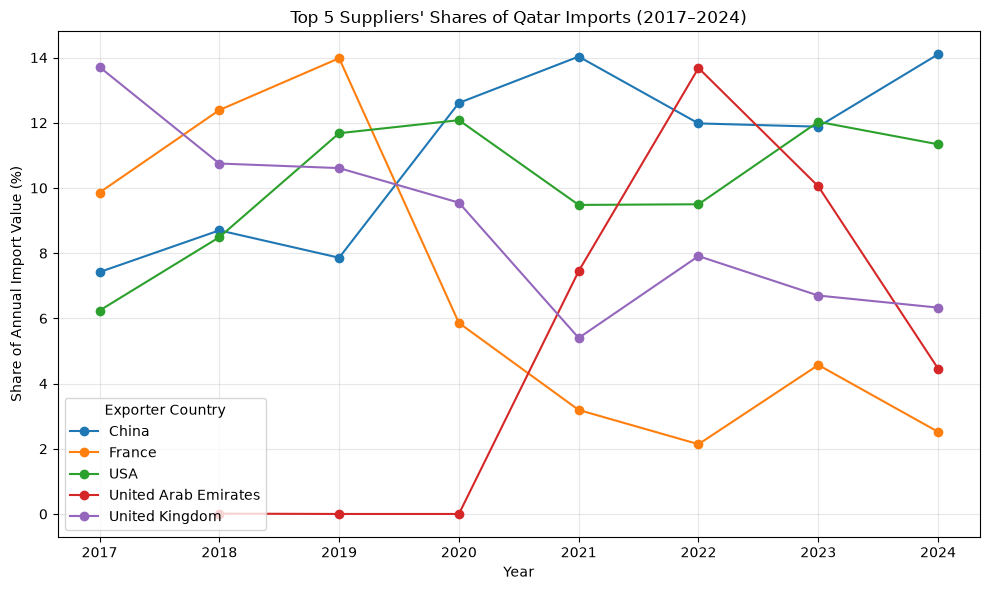

In [11]:

# Question 4: Annual import shares of the top five suppliers
q4 = con.execute("""
    WITH top_five AS (
        SELECT exporter_key
        FROM lake.gold.fact_imports
        GROUP BY exporter_key
        ORDER BY SUM(trade_value) DESC
        LIMIT 5
    ),
    annual_totals AS (
        SELECT
            year_key,
            SUM(trade_value) AS annual_total
        FROM lake.gold.fact_imports
        GROUP BY year_key
    ),
    supplier_totals AS (
        SELECT
            f.year_key,
            f.exporter_key,
            SUM(f.trade_value) AS supplier_total
        FROM lake.gold.fact_imports f
        JOIN top_five t
            ON f.exporter_key = t.exporter_key
        GROUP BY f.year_key, f.exporter_key
    )
    SELECT
        y.year,
        e.country_name AS exporter_country,
        ROUND(
            100.0 * s.supplier_total
            / NULLIF(a.annual_total, 0),
            2
        ) AS import_share_pct
    FROM supplier_totals s
    JOIN annual_totals a
        ON s.year_key = a.year_key
    JOIN lake.gold.dim_year y
        ON s.year_key = y.year_key
    JOIN lake.gold.dim_exporter e
        ON s.exporter_key = e.exporter_key
    ORDER BY y.year, exporter_country
""").df()

display(q4)

# Visualization 4: Supplier import-share trends
plt.figure(figsize=(10, 6))

for country, group in q4.groupby("exporter_country"):
    plt.plot(
        group["year"],
        group["import_share_pct"],
        marker="o",
        label=country
    )

plt.title("Top 5 Suppliers' Shares of Qatar Imports (2017–2024)")
plt.xlabel("Year")
plt.ylabel("Share of Annual Import Value (%)")
plt.xticks(sorted(q4["year"].unique()))
plt.legend(title="Exporter Country")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation — Question 4**

The analysis reveals significant changes in Qatar's major import suppliers between 2017 and 2024. China's share of Qatar's annual import value increased from approximately **7.4% in 2017** to **14.10% in 2024**, making it the largest supplier among the five countries by the end of the period. The United States also increased its share from approximately **6.2% to 11.34%**. In contrast, the United Kingdom's share declined from approximately **13.7% to 6.33%**, while France's share decreased from approximately **9.8% to 2.52%**. The United Arab Emirates showed considerable fluctuations, reaching approximately **13.7% in 2022** before declining to **4.46% in 2024**. Overall, these findings suggest a shift in the relative importance of Qatar's major import suppliers, with China and the United States gaining share while several European suppliers experienced declines.